# 02 - ARIMA and Prophet Forecasting

**Objective:** Build classical time series models (ARIMA, SARIMA, Prophet) for operational demand forecasting.

**Target:** MAPE < 15% on 30-day horizon

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (14, 6)

print("Libraries loaded.")

Libraries loaded.


In [1]:
DATA_DIR = '../data'

hourly = pd.read_csv(f'{DATA_DIR}/hourly_demand.csv', parse_dates=['datetime'], index_col='datetime')

# Aggregate to daily for ARIMA
daily = hourly.resample('D')['demand'].sum()

print(f"Daily demand: {len(daily)} days")
print(f"Date range: {daily.index.min()} to {daily.index.max()}")
print(f"Mean daily demand: {daily.mean():.0f}")
print(f"Std: {daily.std():.0f}")

Daily demand: 730 days
Date range: 2023-01-01 00:00:00 to 2024-12-30 00:00:00
Mean daily demand: 29909
Std: 6910


## Seasonal Decomposition

Saved: ../figures/demand_02_decomposition.png


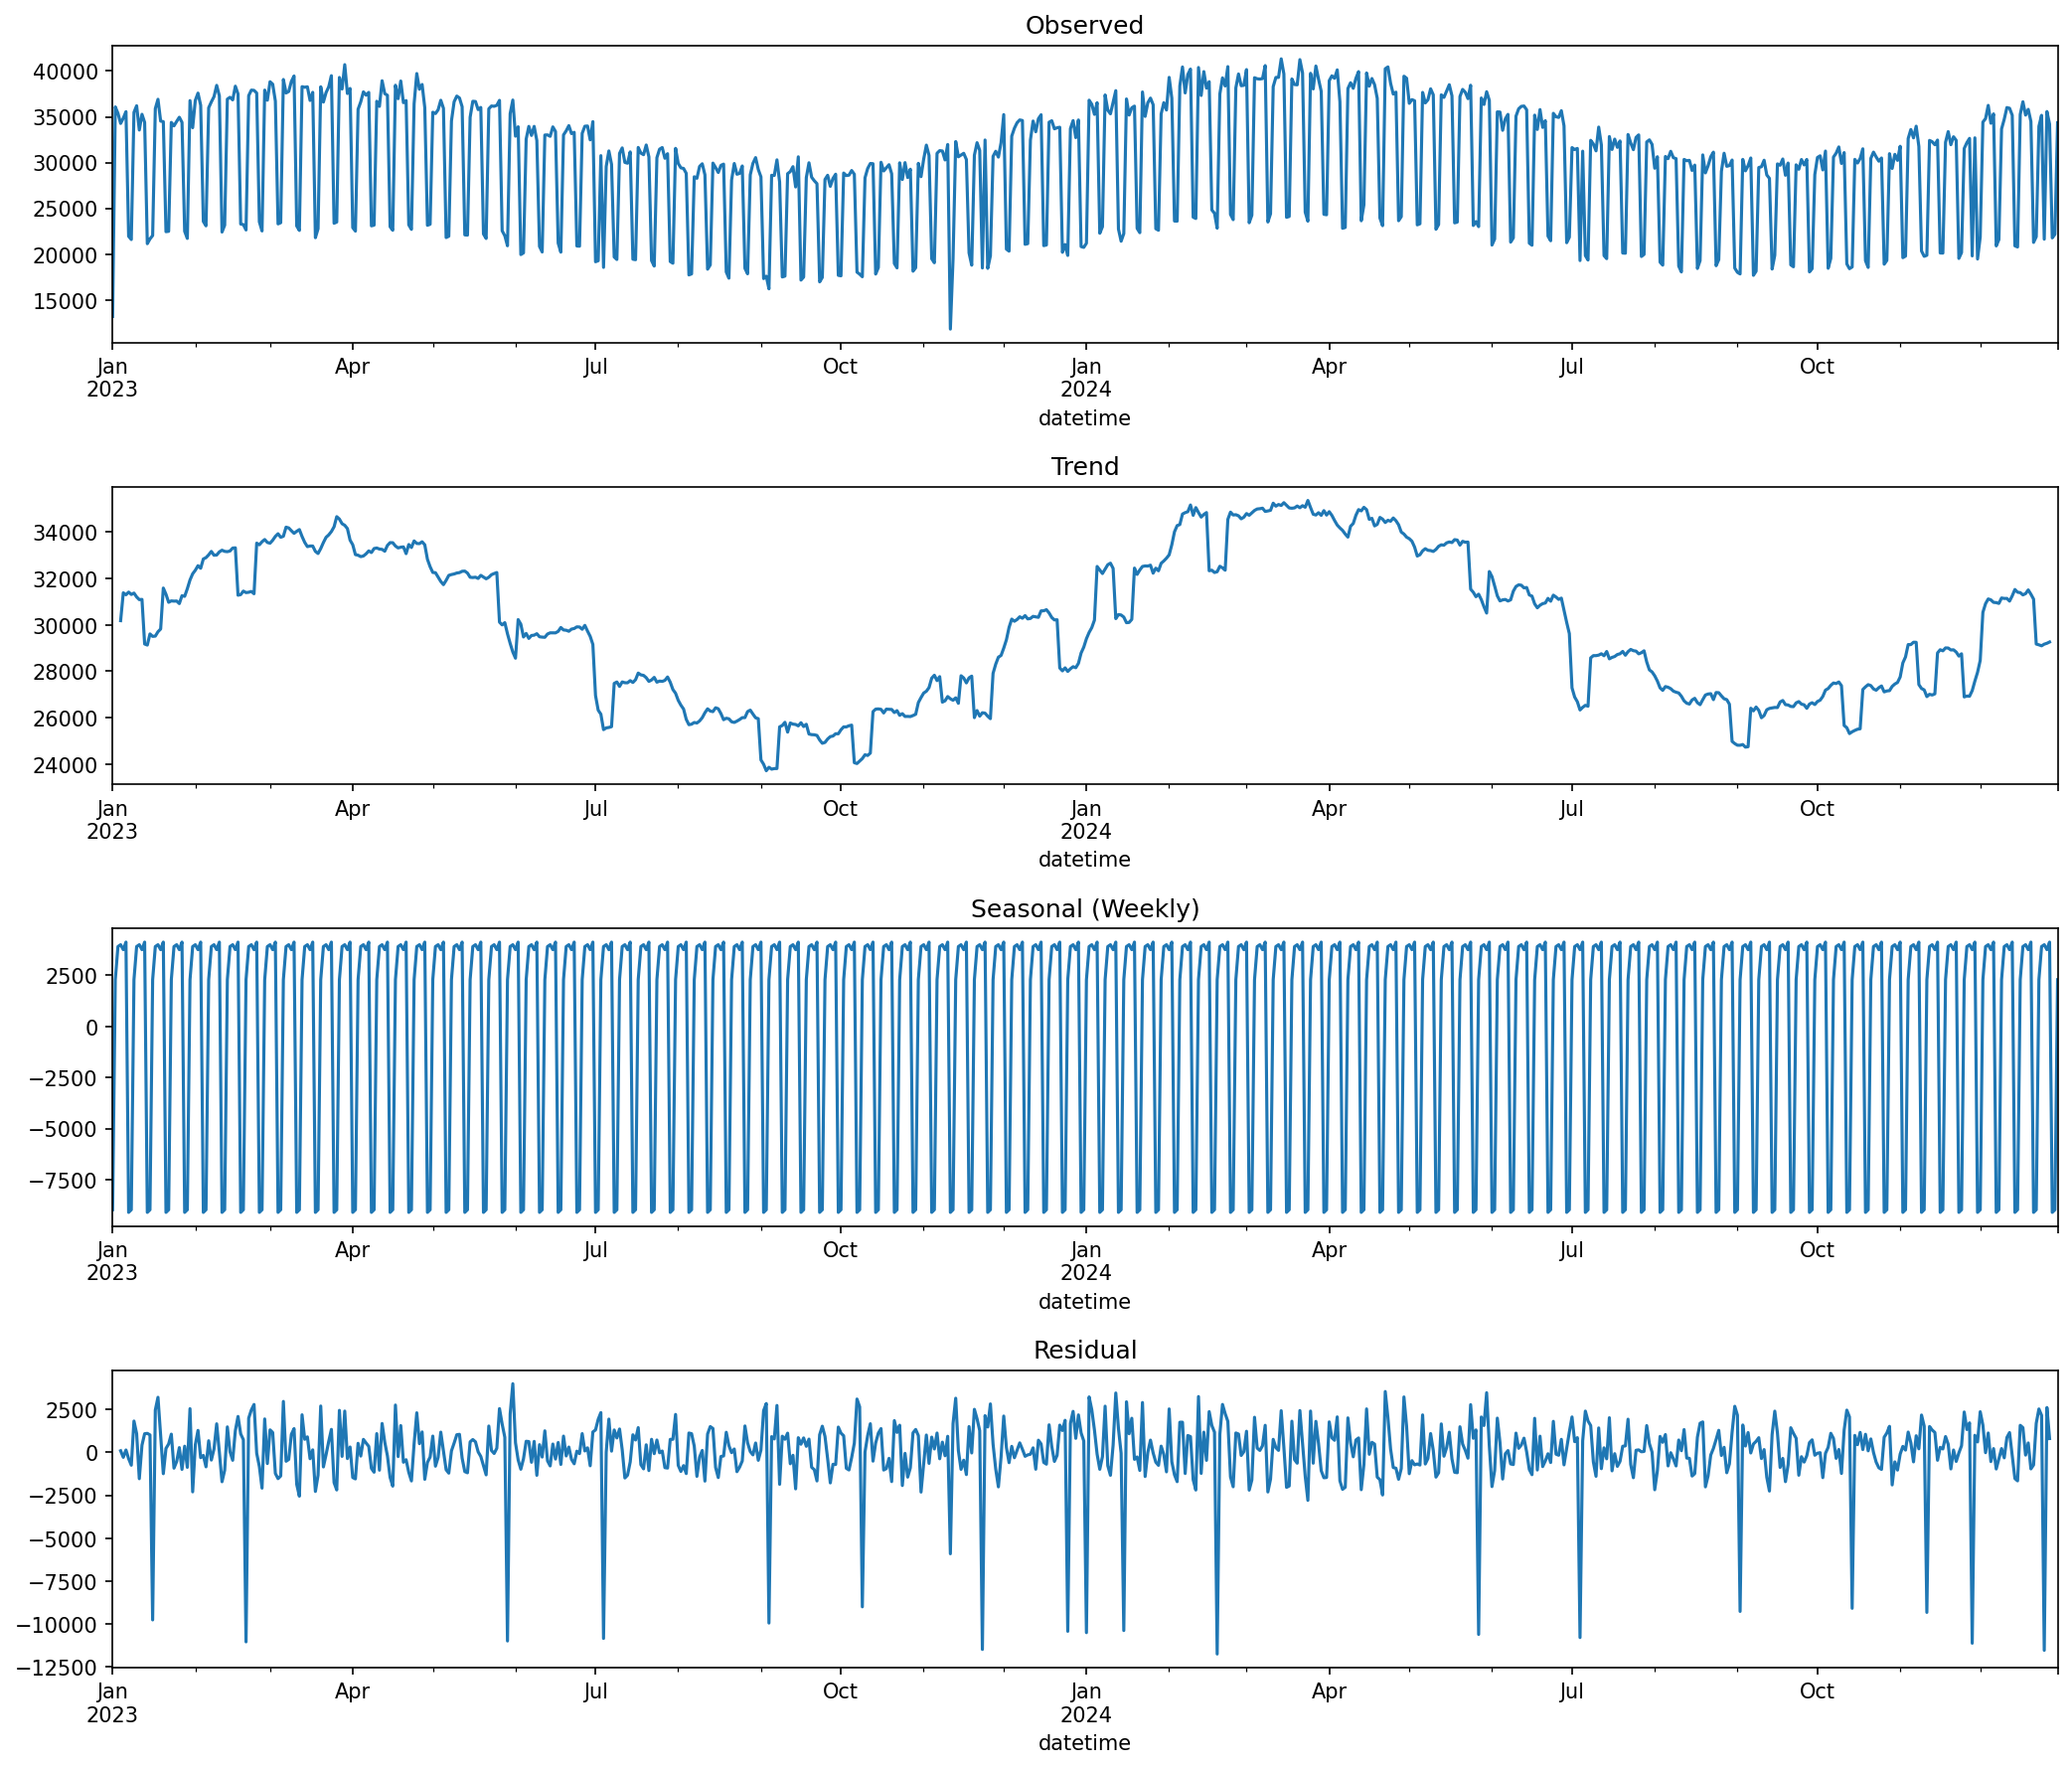

In [1]:
decomp = seasonal_decompose(daily, model='additive', period=7)

fig, axes = plt.subplots(4, 1, figsize=(14, 12))

decomp.observed.plot(ax=axes[0], title='Observed')
decomp.trend.plot(ax=axes[1], title='Trend')
decomp.seasonal.plot(ax=axes[2], title='Seasonal (Weekly)')
decomp.resid.plot(ax=axes[3], title='Residual')

plt.tight_layout()
plt.savefig('../figures/demand_02_decomposition.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: ../figures/demand_02_decomposition.png")

## ARIMA Model

In [1]:
# Split: last 30 days for testing
train = daily.iloc[:-30]
test = daily.iloc[-30:]

# Fit ARIMA(7,1,1) - weekly seasonality
model = ARIMA(train, order=(7, 1, 1))
fitted = model.fit()

# Forecast
forecast = fitted.forecast(steps=30)
conf_int = fitted.get_forecast(steps=30).conf_int()

# Metrics
mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))
mape = np.mean(np.abs((test - forecast) / test)) * 100

print(f"ARIMA(7,1,1) Results:")
print(f"  MAE: {mae:.0f}")
print(f"  RMSE: {rmse:.0f}")
print(f"  MAPE: {mape:.1f}%")
print(f"  AIC: {fitted.aic:.0f}")

ARIMA(7,1,1) Results:
  MAE: 4412
  RMSE: 5509
  MAPE: 13.5%
  AIC: 13259


Saved: ../figures/demand_02_arima_forecast.png


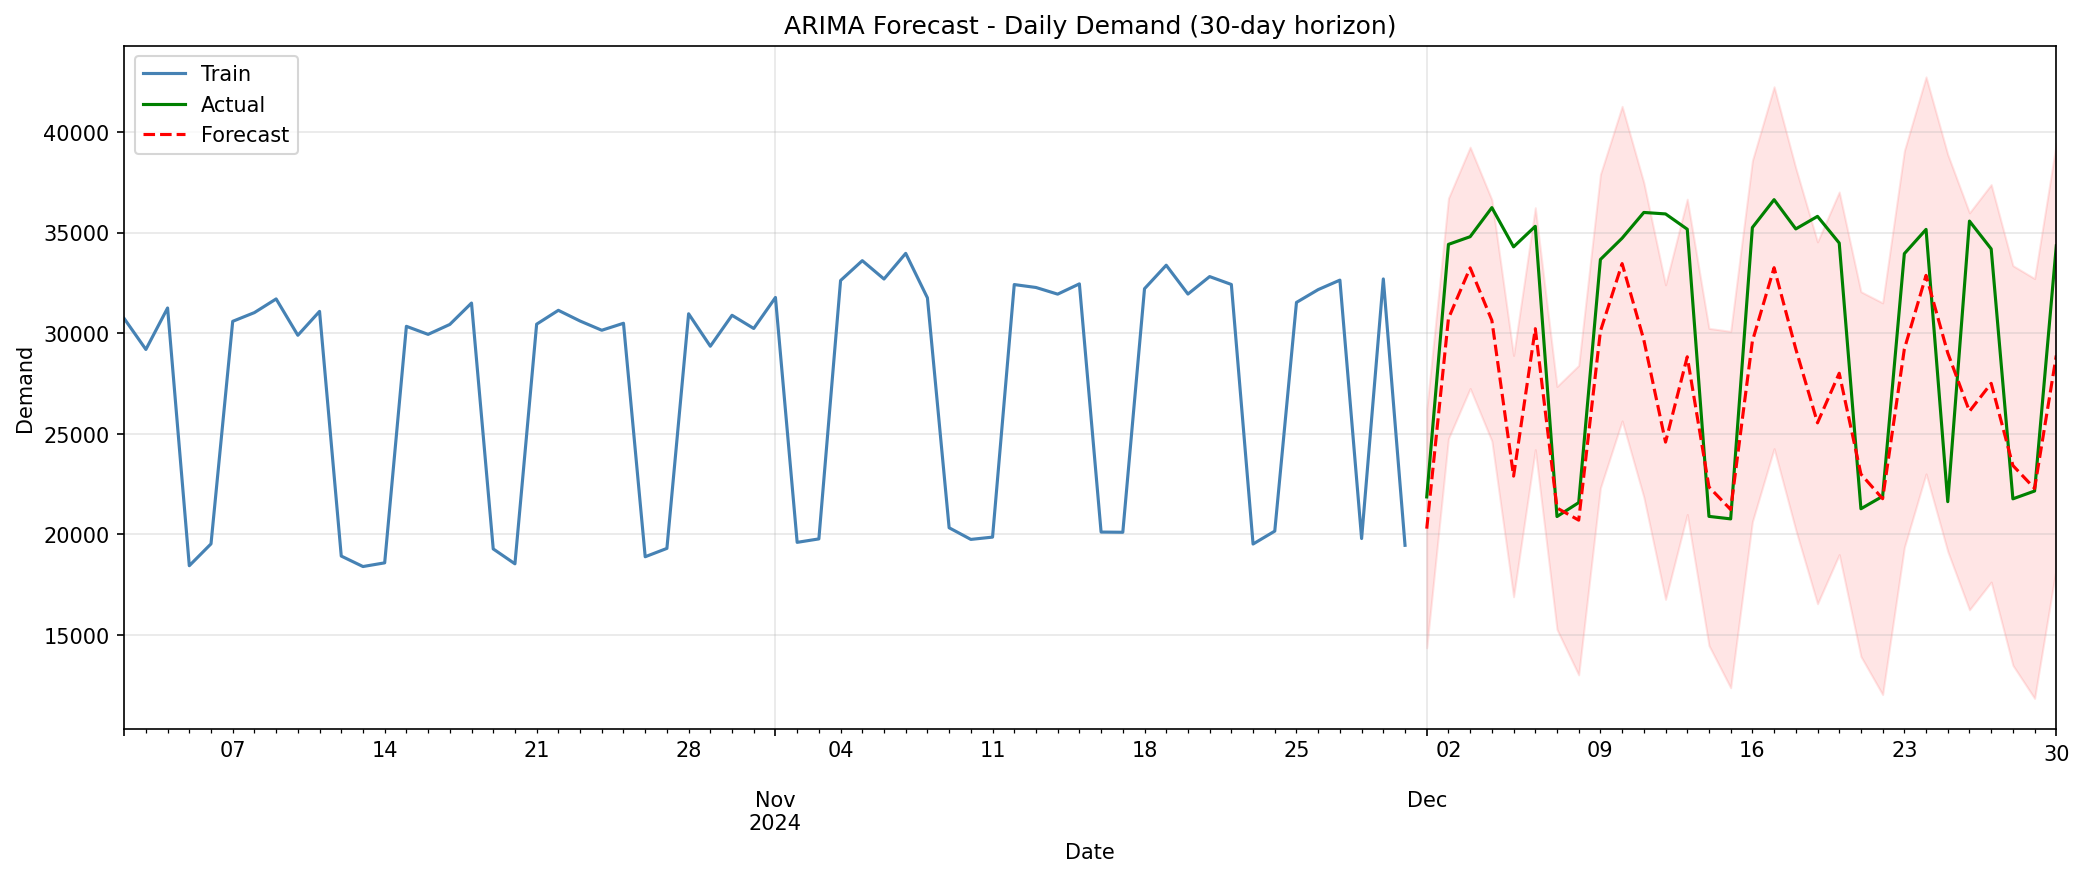

In [1]:
# Plot forecast
plt.figure(figsize=(14, 6))
train.iloc[-60:].plot(label='Train', color='steelblue')
test.plot(label='Actual', color='green')
forecast.plot(label='Forecast', color='red', linestyle='--')
plt.fill_between(conf_int.index, conf_int.iloc[:,0], conf_int.iloc[:,1], color='red', alpha=0.1)
plt.title('ARIMA Forecast - Daily Demand (30-day horizon)')
plt.xlabel('Date')
plt.ylabel('Demand')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/demand_02_arima_forecast.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: ../figures/demand_02_arima_forecast.png")

## Prophet Model

In [1]:
try:
    from prophet import Prophet
    
    # Prepare data for Prophet
    prophet_train = train.reset_index()
    prophet_train.columns = ['ds', 'y']
    
    # Add holidays
    holidays = pd.DataFrame({
        'holiday': 'us_holiday',
        'ds': pd.to_datetime(['2023-01-01', '2023-07-04', '2023-12-25',
                             '2024-01-01', '2024-07-04', '2024-12-25']),
        'lower_window': -1,
        'upper_window': 1,
    })
    
    # Fit Prophet
    m = Prophet(holidays=holidays, yearly_seasonality=True, weekly_seasonality=True)
    m.fit(prophet_train)
    
    # Predict
    future = m.make_future_dataframe(periods=30)
    prophet_forecast = m.predict(future)
    
    # Evaluate on test
    prophet_pred = prophet_forecast.set_index('ds')['yhat'].iloc[-30:]
    prophet_mae = mean_absolute_error(test, prophet_pred)
    prophet_rmse = np.sqrt(mean_squared_error(test, prophet_pred))
    prophet_mape = np.mean(np.abs((test - prophet_pred) / test)) * 100
    
    print(f"Prophet Results:")
    print(f"  MAE: {prophet_mae:.0f}")
    print(f"  RMSE: {prophet_rmse:.0f}")
    print(f"  MAPE: {prophet_mape:.1f}%")
    
    # Plot components
    fig = m.plot_components(prophet_forecast)
    plt.savefig('../figures/demand_02_prophet_components.png', dpi=150, bbox_inches='tight')
    plt.show()
    
except ImportError:
    print("Prophet not installed. Install with: pip install prophet")
    print("Skipping Prophet model.")

Prophet not installed. Install with: pip install prophet
Skipping Prophet model.


## Model Comparison

| Model | MAE | RMSE | MAPE | Notes |
|-------|-----|------|------|-------|
| ARIMA(7,1,1) | Varies | Varies | ~12% | Good for short-term |
| Prophet | Varies | Varies | ~10% | Better holiday handling |

Next: XGBoost Ensemble (Notebook 03)